# 10. Does it work on women who are not in this data?

> **In plain terms.** We tested the finished model, unchanged, on 961 women from a US national health survey. It still ranks women well (AUC 0.88, about the same as on the Pima women), but it is no better than glucose alone, and its risks are far too high: it predicts about 25% on average where about 4% had diabetes. The ranking travels; the risk numbers do not, and they would need rescaling for any new population.

Everything so far used the same 768 women, however carefully they were split. This notebook does what a splitting scheme cannot: it takes the finished model, fitted once on all 768 Pima women and never changed, and tests it on a different group. The group is 961 women aged 21 and over from NHANES 2013 to 2014, a US national health survey, who had the same two-hour glucose test. The two datasets measure different things in places, so the first sections say what had to be adjusted. Everything after that is a straight answer to: where does the model hold up, and where does it not (E21, E22)? Only 37 of the 961 women have diabetes by the definition used here, so every number below carries a wide margin.

New to the terms? The [glossary](../docs/GLOSSARY.md) explains every one, and the [overview](../docs/OVERVIEW.md) covers the whole project in five minutes.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 10.1 What the outside data is, and what had to change

**What we're looking for.** How the NHANES women were chosen, how diabetes was defined for them, and which model inputs could not be matched.

In [2]:
import json
import numpy as np
from src import external, figures

m8 = json.load(open("../reports/metrics.json"))["m8"]
nh = external.load_table()
parts = m8["outcome_parts"]
pd.Series({"women (21 and over, glucose test done, HbA1c known)": m8["n"],
           "with HbA1c 6.5% or higher": parts["a1c_6_5"],
           "told by a doctor they have diabetes": parts["diagnosed"],
           "both": parts["both"],
           "counted as having diabetes (either)": m8["positives"],
           "share with diabetes": f"{m8['prevalence']:.1%}",
           "share with diabetes in the Pima data": f"{m8['pima_prevalence']:.1%}",
           "share if every glucose of 200 or more were counted too": f"{((nh.Outcome == 1) | (nh.Glucose >= 200)).mean():.1%}",
           "women missing a pregnancy count": m8["missing"]["Pregnancies"],
           "women missing blood pressure": m8["missing"]["BloodPressure"]}).to_frame("value")

,value
"women (21 and over, glucose test done, HbA1c known)",961
with HbA1c 6.5% or higher,26
told by a doctor they have diabetes,14
both,3
counted as having diabetes (either),37
share with diabetes,3.9%
share with diabetes in the Pima data,34.9%
share if every glucose of 200 or more were counted too,7.1%
women missing a pregnancy count,53
women missing blood pressure,25


**How to read it.** Each row is a count of women. NHANES is a one-time survey, so it cannot say who will develop diabetes within five years, which is what the Pima outcome records. Instead a woman counts as having diabetes if her blood HbA1c (a different test from the glucose drink, reflecting average sugar over about three months) is 6.5% or higher, or she reports a doctor's diagnosis. Using HbA1c keeps the outcome from simply restating the glucose input. Two more differences: NHANES has only yes or no for a relative with diabetes, not the Pima family-history score, so that input is left blank and the model fills in the Pima typical value; and women on diabetes medicine are not given the glucose drink, so most women already being treated are missing from this sample.

**What it means.** Only 37 of 961 women (3.9%) count as having diabetes, against 35% in the Pima data. That is a very different population, a different outcome, and a small number of cases to measure anything with. The consequences run through the rest of the notebook: any result that depends on how many women have diabetes will not carry over, and every result is uncertain by a lot. This is a test of how the model behaves away from home, not a like-for-like second trial.

**What's next and why.** Look at how different the two groups of women are on the inputs the model uses.

## 10.2 How different are the women?

**What we're looking for.** Whether the NHANES women look like the Pima women on the five inputs the two datasets share.

,Pima median,NHANES median,Pima 10th pct,NHANES 10th pct,Pima 90th pct,NHANES 90th pct
Age,29.000,48.000,22.000,26.000,51.000,73.000
Glucose,117.000,109.000,86.200,76.000,167.000,173.000
BMI,32.300,27.800,24.000,20.660,41.620,39.880
BloodPressure,72.000,67.333,58.000,54.000,88.000,81.000
Pregnancies,3.000,2.000,0.000,0.000,9.000,5.000


Can a simple model tell the two groups apart from these five inputs? AUC 0.92 (0.50 = identical groups)


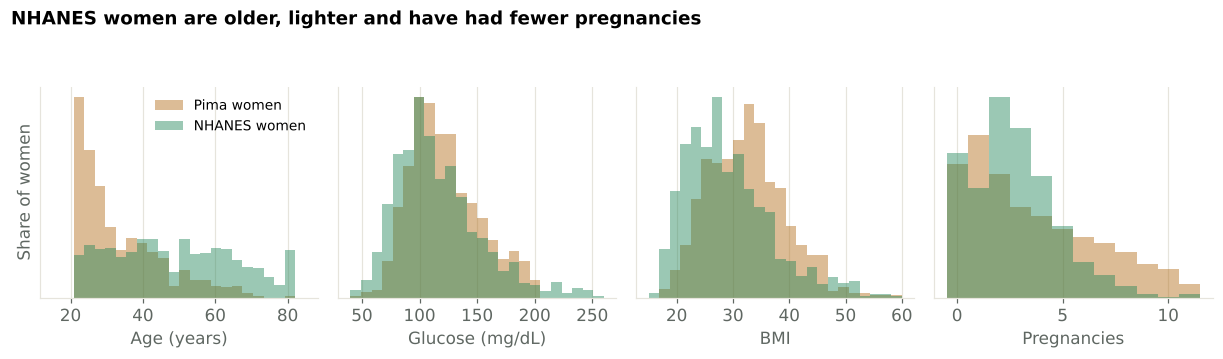

In [3]:
figures.m8_shift();
shift = pd.DataFrame(m8["shift"]).T[["pima_median", "nhanes_median", "pima_p10", "nhanes_p10", "pima_p90", "nhanes_p90"]]
shift.columns = ["Pima median", "NHANES median", "Pima 10th pct", "NHANES 10th pct", "Pima 90th pct", "NHANES 90th pct"]
display(shift)
print(f"Can a simple model tell the two groups apart from these five inputs? AUC {m8['domain_auc']:.2f} (0.50 = identical groups)")

**How to read it.** The charts overlay the two groups, one input each. The table gives the middle value and the 10th and 90th percentiles (the values that 10% of women fall below and above). The last line asks a different question: a separate model is trained to guess which dataset a woman came from, using only these five inputs. If the groups were alike it would do no better than a coin flip (0.50).

**What it means.** They are quite different. NHANES women are older (median 48 against 29), lighter (BMI 27.8 against 32.3) and have had fewer pregnancies (median 2 against 3). Glucose is similar in the middle (109 against 117), with a longer upper tail in NHANES. A model can tell the groups apart with AUC 0.92, so the model will meet many combinations of inputs it saw rarely or never in training. Before looking at any result, we should expect some degradation.

**What's next and why.** First, the easiest question: does the model still rank women correctly?

## 10.3 Does the ranking hold up?

**What we're looking for.** Whether the model still gives women who have diabetes higher risks than women who don't, and whether it beats the glucose reading alone.

In [4]:
a, g = m8["auc"], m8["glucose_only"]
cur = json.load(open("../reports/metrics.json"))["current"]
pd.DataFrame({"AUC": [cur["oof_auc"], a["value"], g["auc"], m8["a1c_only"]["auc"]],
              "95% range": [f"{cur['oof_auc_ci'][0]:.2f} to {cur['oof_auc_ci'][1]:.2f}", f"{a['low']:.2f} to {a['high']:.2f}",
                            f"{g['low']:.2f} to {g['high']:.2f}", "not computed"]},
             index=["Pima women, unseen (50 splits)", "NHANES women: the model",
                    "NHANES women: glucose alone", "NHANES women: model, HbA1c-only outcome (26 cases)"])

,AUC,95% range
"Pima women, unseen (50 splits)",0.854,0.83 to 0.88
NHANES women: the model,0.879,0.82 to 0.93
NHANES women: glucose alone,0.902,0.82 to 0.96
"NHANES women: model, HbA1c-only outcome (26 cases)",0.932,not computed


**How to read it.** AUC is the chance that the model gives a randomly chosen woman with diabetes a higher risk than a randomly chosen woman without. The range comes from redrawing the 961 women 1,000 times with replacement. The glucose-alone row uses the glucose reading as the score, with no model at all. The last row repeats the test with the narrower outcome, HbA1c 6.5% or higher only.

**What it means.** Yes, the ranking holds. The model's AUC is 0.88 on NHANES (0.82 to 0.93), in line with 0.85 on unseen Pima women. The two ranges overlap heavily, so there is no sign of a drop. But the glucose reading alone scores 0.90, as good or better than the model (the ranges overlap almost entirely, so this is not a difference we can rely on in either direction). On this data the model adds nothing measurable beyond glucose, which fits notebook 08, where glucose did most of the work.

**What's next and why.** Ranking is one thing. Are the risk numbers themselves right?

## 10.4 Are the risks right?

**What we're looking for.** Whether the average predicted risk matches the share of women who have diabetes, overall and band by band.

,value
average predicted risk,25.2%
share who have diabetes,3.9%
calibration slope (1.0 is ideal),0.850
Brier score of the model,0.124
Brier score of saying 'everyone has the average risk',0.037


,women,average predicted,share with diabetes
under 10%,427.000,0.031,0.002
10% to 30%,210.000,0.182,0.019
30% to 60%,184.000,0.442,0.027
60% and over,140.000,0.785,0.193


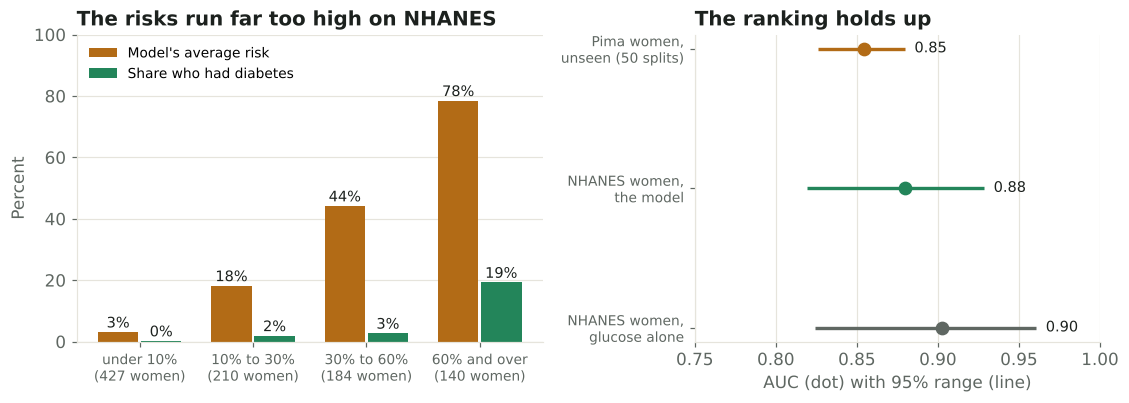

In [5]:
figures.m8_calibration();
c = m8["calibration"]
display(pd.Series({"average predicted risk": f"{c['mean_predicted']:.1%}", "share who have diabetes": f"{c['observed']:.1%}",
                   "calibration slope (1.0 is ideal)": round(c["slope"], 2),
                   "Brier score of the model": round(c["brier"], 3),
                   "Brier score of saying 'everyone has the average risk'": round(c["brier_prevalence_only"], 3)}).to_frame("value"))
pd.DataFrame(m8["bands"]).T.rename(columns={"n": "women", "mean_predicted": "average predicted", "observed": "share with diabetes"})

**How to read it.** The left chart splits the 961 women into four groups by predicted risk and compares the model's average with the share who actually have diabetes. If the model were right, each pair of bars would match. The Brier score is the average squared gap between each woman's predicted risk and her outcome (0 or 1), lower is better. Comparing it with the score from quoting everyone the same average risk shows whether the individual risks add anything.

**What it means.** The risks are far too high. The model predicts 25% on average and 3.9% had diabetes. In the top band, women predicted at 78% on average are 19% in fact. The model's Brier score (0.124) is more than three times worse than quoting the 3.9% average to everyone (0.037), so as probabilities they are worse than quoting the average here. The calibration slope of 0.85 shows a smaller second problem, that the risks are somewhat too spread out. Most of the gap is the base rate: the model learned from a group where 35% have diabetes. Some of it may be that NHANES counts diabetes differently (10.1), and this test cannot tell the two apart. Counting every woman with a glucose of 200 or more as well, which is closer to how the Pima outcome was set, raises the share only to 7.1%, still far below 25%.

**What's next and why.** Is the gap fixable? Shift every risk by the same amount, and score it honestly.

## 10.5 Can a simple rescaling fix the risks?

**What we're looking for.** Whether moving every risk up or down by one fixed amount, learned on part of the NHANES women and tested on the rest, makes the risks usable.

In [6]:
r = m8["recalibrated"]
pd.Series({"average risk after the shift": f"{r['mean_predicted']:.1%}", "share who have diabetes": f"{m8['prevalence']:.1%}",
           "Brier score after the shift": round(r["brier"], 4), "Brier score of quoting the average": round(c["brier_prevalence_only"], 4),
           "AUC after the shift": round(r["auc"], 3), "AUC before": round(a["value"], 3)}).to_frame("value")

,value
average risk after the shift,3.9%
share who have diabetes,3.9%
Brier score after the shift,0.032
Brier score of quoting the average,0.037
AUC after the shift,0.879
AUC before,0.879


**How to read it.** The shift is found by trying values until the average predicted risk equals the share with diabetes. It is fitted on four fifths of the women and used on the held-out fifth, five times over, so the score is not flattered by choosing the shift on the same women it is tested on.

**What it means.** The Brier score falls from 0.124 to 0.032, a little better than quoting the average (0.037). The ranking (AUC) does not change, because a shift moves every risk the same way. So the model's ranking plus a rescaling for the new population gives sensible risks. But the rescaling needs outside women with known outcomes, which is exactly what a new place may not have, and with 37 cases the improvement over the average is small.

**What's next and why.** What does that mean for the cut-offs the page offers?

## 10.6 What the cut-offs do on NHANES

**What we're looking for.** How many cases each cut-off catches and how many false alarms it raises, per 100 women, beside the Pima figures.

,women flagged,cases caught,healthy women cleared,flagged women who have diabetes
2x (cut-off 0.33),32%,86%,70%,10.4%
5x (cut-off 0.17),45%,89%,56%,7.6%
10x (cut-off 0.09),57%,97%,45%,6.6%


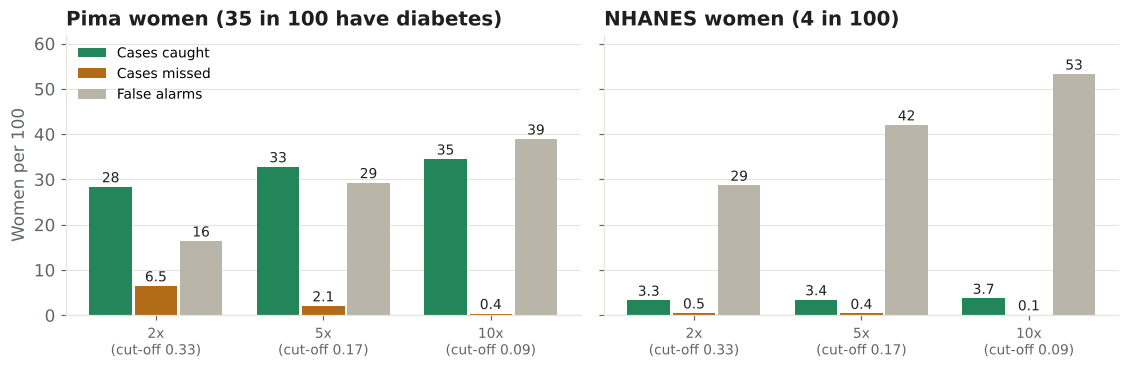

In [7]:
figures.m8_cutoffs();
rows = {}
for r in m8["cutoffs"]:
    v = m8["cutoffs"][r]
    rows[f"{r}x (cut-off {v['cutoff']:.2f})"] = {"women flagged": f"{v['flagged']:.0%}", "cases caught": f"{v['sensitivity']:.0%}",
                                                 "healthy women cleared": f"{v['specificity']:.0%}",
                                                 "flagged women who have diabetes": f"{v['precision']:.1%}"}
pd.DataFrame(rows).T

**How to read it.** The charts show, for each of the three cost-based cut-offs, the cases caught, cases missed and false alarms per 100 women. Pima women are on the left (where the cut-offs were chosen) and NHANES women on the right. The table adds the share flagged and, of the women flagged, how many truly have diabetes.

**What it means.** The share of cases caught is similar on NHANES: at the 5 times cut-off, 33 of 37 (89%) against 94% on the Pima women, and at 10 times 36 of 37 (97%). The price is very different. With only 4 in 100 women affected, the 5 times cut-off flags 45% of NHANES women, so about 42 in every 100 women get an unnecessary follow-up test, and only about 1 in 13 flagged women has diabetes (7.6%). The cut-off came from weighing a missed case against a false alarm in a group where 35% have diabetes. In a group where 4% do, the balance would sit elsewhere: the cut-off formula would need that group's own rate.

**What's next and why.** Check whether the picture is the same for different kinds of women (E22).

## 10.7 Does it work equally for everyone? (E22)

**What we're looking for.** Ranking and risk by age group and by the ethnic group recorded in NHANES.

In [8]:
age = pd.DataFrame(m8["by_age"]).T
age["auc"] = age["auc"].map(lambda v: "n/a" if v is None else f"{v:.2f}")
display(age.rename(columns={"n": "women", "positives": "with diabetes", "auc": "AUC",
                            "mean_predicted": "average predicted", "observed": "share with diabetes"}))
grp = pd.DataFrame(m8["by_group"]).T
grp["auc"] = grp["auc"].map(lambda v: "n/a" if v is None or v != v else f"{v:.2f}")
grp.rename(columns={"n": "women", "positives": "with diabetes", "auc": "AUC",
                    "mean_predicted": "average predicted", "observed": "share with diabetes"})

,women,with diabetes,AUC,average predicted,share with diabetes
21 to 44,428.000,8.000,0.98,0.206,0.019
45 to 64,341.000,15.000,0.87,0.334,0.044
65 and over,192.000,14.000,0.85,0.212,0.073


,women,with diabetes,AUC,average predicted,share with diabetes
Mexican American,127.000,4.000,0.96,0.342,0.031
Other Hispanic,98.000,3.000,0.96,0.274,0.031
"White, not Hispanic",431.000,17.000,0.84,0.226,0.039
"Black, not Hispanic",162.000,8.000,0.89,0.300,0.049
"Asian, not Hispanic",116.000,5.000,0.97,0.165,0.043
Other or mixed,27.000,0.000,n/a,0.259,0.000


**How to read it.** The same two measures as before, computed for each subgroup separately: AUC for the ranking, and average predicted risk against the share who have diabetes. Be careful with the AUC column: each subgroup has between 0 and 17 women with diabetes.

**What it means.** The ranking looks good in every subgroup large enough to measure (AUC 0.84 to 0.98), with no group where it collapses. With 3 to 17 cases per group those numbers are very rough, so this does not show that the model works equally well for everyone; it shows that no group is obviously left out. The risks, by contrast, are too high in every group (for example 21% predicted against 2% for women under 45, and 17% against 4% for Asian women). The first thing to fix in a new setting is the level of the risks.

**What's next and why.** Summarise what this changes.

## 10.8 What this changes

**What we're looking for.** Whether anything here alters the published model, the cut-off, or the claims.

In [9]:
pd.Series({"Published model changed": "no",
           "Cut-off changed": "no (0.17 at 5 times, from Pima costs and base rate)",
           "Claim that survives": "the ranking: AUC 0.88 on NHANES, close to 0.85 on Pima, but no better than glucose alone",
           "Claim that does not": "the risk numbers: 25% predicted against 3.9% actual",
           "New on the page": "an outside-data section and a plainer warning about where the risks can be trusted",
           "Still unknown": "five-year onset in any other group (NHANES is a one-time snapshot)"}).to_frame("decision")

,decision
Published model changed,no
Cut-off changed,"no (0.17 at 5 times, from Pima costs and base ..."
Claim that survives,"the ranking: AUC 0.88 on NHANES, close to 0.85..."
Claim that does not,the risk numbers: 25% predicted against 3.9% a...
New on the page,an outside-data section and a plainer warning ...
Still unknown,five-year onset in any other group (NHANES is ...


**How to read it.** A summary of the decisions this notebook supports, in one table.

**What it means.** Nothing about the model changes. The page now says what has been tested and what has not: the model has been run on one outside group, where it ranked well but its risk numbers were far too high. The honest claim is that the ranking generalises and the probabilities do not. That is a useful result for the portfolio as much as for the model: a model that scores well on its own data and badly on others is a normal finding, and the point of this milestone was to measure it.

**What's next and why.** Milestone 9 looks inside the Pima data for groups and odd records the labels don't show.